In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [ ]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'human', 'CCCA')
pth_res = os.path.join(pth_data, 'results')
pth_clf = os.path.join(pth_res, 'classifier')
pth_out = os.path.join(pth_res, 'cancer', 'CCCA')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'human', 'CCCA')

In [3]:
fn = os.path.join(pth_clf, 'logreg.csv')
beta = pd.read_csv(fn, index_col = 0)
beta

,beta
GSE162534,0.562046
GSE229103,4.880419
rRNAModifications,3.368317
intercept_,1.128921


In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata

AnnData object with n_obs × n_vars = 1406087 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [5]:
scaler = StandardScaler(with_mean = False)
sig = lambda x: 100 / (1 + np.exp(-x))

In [6]:
# predict branches (logreg)
X = adata.obs[beta.index[:-1]]
X = pd.DataFrame(scaler.fit_transform(X),
                 index = X.index,
                 columns = X.columns)
X['intercept_'] = 1.
prob = X.dot(beta).apply(sig)
adata.obs['Branch2'] = prob
adata.obs['Branch1'] = 100 - prob

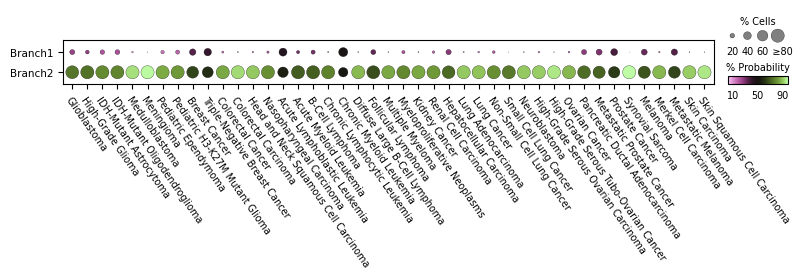

In [7]:
ix = (adata.obs.groupby(
      ['Category', 'Disease'], observed = True)
      .first().reset_index().Disease)

# probabilities dotplot
fs, var = 7, ['Branch1', 'Branch2']
dp = sc.pl.dotplot(adata, var, 'Disease',
                   categories_order = ix,
                   expression_cutoff = 50,
                   dot_max = .8,
                   vcenter = 50,
                   cmap = 'vanimo',
                   figsize = (9.5, .575),
                   swap_axes = True,
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 90,
         x_padding = .6,
         y_padding = .6)
dp.legend(width = .8)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs, pad = -11)
ax_size.tick_params('x', size = 0, labelsize = fs, pad = .8)
ax_size.set_xticklabels(['20', '40', '60', '   ≥80'])
cax.set_title('% Probability', size = fs, pad = 4.5)
cax.set_xticks([10, 50, 90])
cax.tick_params('x', size = 0, labelsize = fs, pad = 4)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([.985 * pos_size.x0,
                      pos_main.y0 + .9 * pos_main.height,
                      pos_size.width,
                      .8 * pos_main.height])

cax.set_position([.985 * pos_color.x0,
                  pos_main.y0,
                  pos_color.width,
                  .185 * pos_main.height])

ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        rotation = -55, fontsize = fs,
                        rotation_mode = 'anchor',
                        ha = 'left')
ax_main.tick_params('y', labelsize = fs + .5)

fn = os.path.join(pth_fig, 'probabilities.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [11]:
# save results
df = (adata.obs
      .groupby(['Category', 'Disease'], observed = True)
      [['Branch1', 'Branch2']].mean())
df.to_csv(os.path.join(pth_out, 'probabilities.csv'))

In [8]:
adata.write(os.path.join(pth_in, 'probabilities.h5ad'))